In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("imdb_movies_2000to2022.actorXgenre (1).csv")

X = df.drop(columns=["actor_id"]).select_dtypes(
    include="number"
).fillna(0)

print(df.shape)
print(df.head())

(33609, 26)
    actor_id  Comedy  Fantasy  Romance  Drama  Mystery  Thriller  Action  \
0  nm0000212     7.0      1.0      6.0    6.0      1.0       2.0     1.0   
1  nm0413168     7.0      3.0      5.0   12.0      5.0       2.0    14.0   
2  nm0000630     8.0      2.0      6.0   14.0      2.0       3.0     4.0   
3  nm0005227    10.0      1.0      2.0    2.0      0.0       1.0     1.0   
4  nm0864851     1.0      0.0      0.0    0.0      0.0       0.0     0.0   

   Biography  Crime  ...  Horror  Documentary  Sport  News  Family  Music  \
0        1.0    2.0  ...     0.0          0.0    0.0   0.0     0.0    0.0   
1        4.0    6.0  ...     0.0          0.0    0.0   0.0     0.0    0.0   
2        5.0    1.0  ...     3.0          7.0    3.0   1.0     0.0    0.0   
3        0.0    0.0  ...     1.0          0.0    1.0   0.0     2.0    0.0   
4        0.0    0.0  ...     1.0          0.0    0.0   0.0     0.0    0.0   

   Unnamed: 22  Western  Short  Reality-TV  
0          0.0      0.0

In [5]:
inertias = []

for k in range(2, 31):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)
    inertias.append(model.inertia_)

    print(f"k={k}, inertia={model.inertia_:.2f}")

k=2, inertia=391327.87
k=3, inertia=333284.71
k=4, inertia=307978.70
k=5, inertia=290944.58
k=6, inertia=275595.72
k=7, inertia=261838.99
k=8, inertia=250705.90
k=9, inertia=239043.66
k=10, inertia=230642.85
k=11, inertia=225399.99
k=12, inertia=218396.20
k=13, inertia=211139.04
k=14, inertia=205369.37
k=15, inertia=199501.60
k=16, inertia=197957.92
k=17, inertia=193025.18
k=18, inertia=189004.90
k=19, inertia=185774.34
k=20, inertia=181895.23
k=21, inertia=176865.01
k=22, inertia=176209.12
k=23, inertia=173909.05
k=24, inertia=170401.20
k=25, inertia=169235.52
k=26, inertia=166527.05
k=27, inertia=162971.70
k=28, inertia=161890.59
k=29, inertia=158967.40
k=30, inertia=157688.87


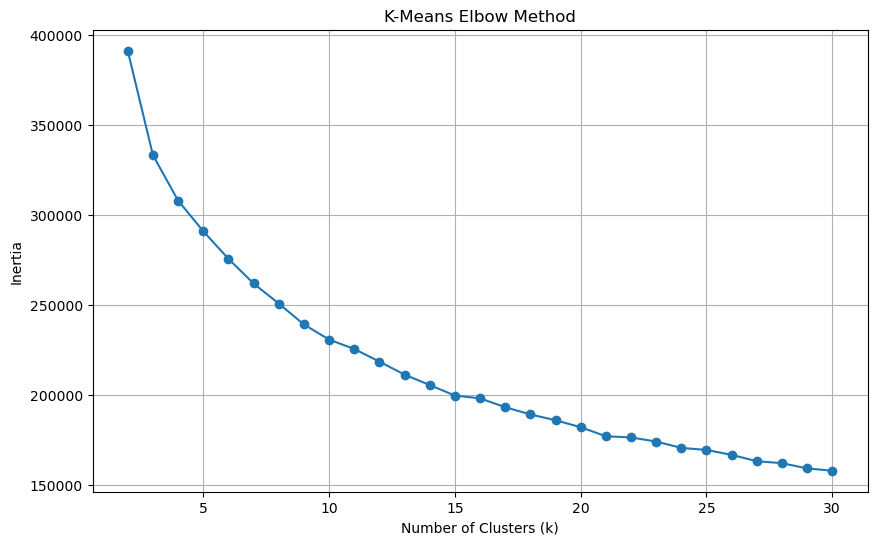

In [6]:
plt.figure(figsize=(10, 6))
plt.plot(range(2, 31), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.grid(True)
plt.show()

X_sample = X.sample(n=5000, random_state=42)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

dbscan = DBSCAN(eps=2.5, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

n_clusters = len(set(labels) - {-1})

print("Number of clusters:", n_clusters)
print("Noise points:", sum(labels == -1))

In [ ]:
results = df.loc[X_sample.index].copy()
results["cluster"] = labels

for cluster in sorted(set(labels)):
    if cluster == -1:
        continue

    actors = results[results["cluster"] == cluster]

    print(f"\nCluster {cluster}")
    print(
        actors["actor_id"].sample(
            n=min(5, len(actors)),
            random_state=42
        ).to_string(index=False)
    )